In [4]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy, generate_momentum_signal

In [5]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

In [6]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)
momentum_signal = generate_momentum_signal(prices, lookback)
momentum_position = momentum_df["position"]

In [7]:
run_boundaries = []

run_boundaries.append(lookback + 1)

for i in range(lookback + 2, len(momentum_position)):
    if momentum_position.iloc[i] != momentum_position.iloc[i - 1]:
        run_boundaries.append(i)

run_boundaries.append(len(momentum_position))

In [8]:
run_lengths = []

for i in range(1, len(run_boundaries)):
    difference = float(run_boundaries[i]) - float(run_boundaries[i - 1])

    run_lengths.append(difference)

In [9]:
cash_runs = run_lengths[::2]
invested_runs = run_lengths[1::2]

In [11]:
def generate_random_signal_v5(cash_runs, invested_runs, lookback):

    random_cash_sequence = np.random.permutation(cash_runs).astype(int)
    random_invested_sequence = np.random.permutation(invested_runs).astype(int)

    sequence = []
        
    for i in range(len(cash_runs)):
        
        sequence.extend([0] * random_cash_sequence[i])
        sequence.extend([1] * random_invested_sequence[i])
    
    sequence.append(np.nan)
    
    random_signal = ([np.nan] * lookback) + sequence

    return random_signal

In [14]:
def run_simulation_v5(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v5(cash_runs, invested_runs, 252)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result

In [15]:
%timeit run_simulation_v5(1)

3.6 ms ± 114 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [24]:
np.random.seed(44)

simulation_output = run_simulation_v5(100000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,10.880236,0.101357,0.137969,0.768838,-0.313847,0.322950,0.775232,89
1,5.539611,0.076005,0.161014,0.535479,-0.367422,0.206859,0.775232,89
2,4.644221,0.069842,0.174890,0.473505,-0.536205,0.130252,0.775232,89
3,3.623271,0.061547,0.163593,0.446895,-0.551895,0.111519,0.775232,89
4,3.431431,0.059793,0.172358,0.423175,-0.551895,0.108342,0.775232,89
...,...,...,...,...,...,...,...,...
99995,5.694756,0.076989,0.172809,0.515731,-0.564813,0.136309,0.775232,89
99996,2.243434,0.046969,0.181375,0.343790,-0.596809,0.078701,0.775232,89
99997,9.180905,0.094745,0.155471,0.660175,-0.422290,0.224360,0.775232,89
99998,3.007847,0.055648,0.175584,0.396344,-0.548294,0.101493,0.775232,89


In [19]:
def summary(simulation_df, momentum_results, plot_title):

    print(f"Sharpe Average: {simulation_df['annual_sharpe'].mean():.4f}")
    print(f"Sharpe Median:  {simulation_df['annual_sharpe'].median():.4f}")
    print(f"Largest Sharpe: {simulation_df['annual_sharpe'].max():.4f}")
    print(f"Average No. of Trades: {simulation_df['trades'].mean():.4f}")
    print(f"Average Time Invested: {simulation_df['time_invested'].mean():.4f}")

    fraction_numerator = 0

    simulation_sharpe_ratio = simulation_df["annual_sharpe"]

    for i in range(len(simulation_sharpe_ratio)):
        if simulation_sharpe_ratio[i] >= momentum_results["annual_sharpe"]:
            fraction_numerator += 1

    p_value = fraction_numerator/len(simulation_sharpe_ratio)

    print("Empirical p-value:", p_value)

    plt.figure(figsize=(8, 5))

    plt.hist(
        simulation_df["annual_sharpe"],
        bins=40,
        color="black",
        alpha=0.75,
        edgecolor="white"
    )

    plt.axvline(
        momentum_results["annual_sharpe"],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Momentum Sharpe"
    )

    plt.xlabel("Sharpe Ratio")
    plt.ylabel("Frequency")
    plt.title(plot_title)

    plt.legend()

    plt.grid(axis="y", alpha=0.2)

    plt.tight_layout()
    plt.show()

Sharpe Average: 0.4751
Sharpe Median:  0.4607
Largest Sharpe: 0.9277
Average No. of Trades: 89.0000
Average Time Invested: 0.7752
Empirical p-value: 0.0799


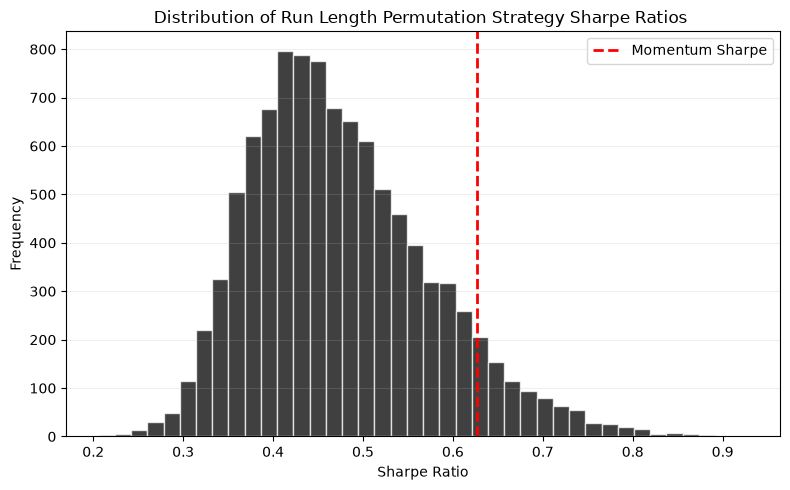

In [23]:
summary(simulation_df, momentum_results, "Distribution of Run Length Permutation Strategy Sharpe Ratios ")